# Predict House Pricing in Ames lowa for 12 features

## Import Libraries

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Fetch the data

In [45]:
df = pd.read_excel('HousePricePrediction.xlsx')

In [46]:
# We have 2919 observation and 12 featuer , 1 target output 
df.shape

(2919, 13)

In [47]:
# We noticed that we have some missing values and there is a numerical and categorical data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Id            2919 non-null   int64  
 1   MSSubClass    2919 non-null   int64  
 2   MSZoning      2915 non-null   object 
 3   LotArea       2919 non-null   int64  
 4   LotConfig     2919 non-null   object 
 5   BldgType      2919 non-null   object 
 6   OverallCond   2919 non-null   int64  
 7   YearBuilt     2919 non-null   int64  
 8   YearRemodAdd  2919 non-null   int64  
 9   Exterior1st   2918 non-null   object 
 10  BsmtFinSF2    2918 non-null   float64
 11  TotalBsmtSF   2918 non-null   float64
 12  SalePrice     1460 non-null   float64
dtypes: float64(3), int64(6), object(4)
memory usage: 296.6+ KB


In [48]:
# almost the SalePrice target have nulls more that half
df.isnull().sum(axis=0)

Id                 0
MSSubClass         0
MSZoning           4
LotArea            0
LotConfig          0
BldgType           0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
Exterior1st        1
BsmtFinSF2         1
TotalBsmtSF        1
SalePrice       1459
dtype: int64

In [49]:
df.head()

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0


## Clean and Explore the data

In [50]:
df_cleanna = df.dropna() 
print(df_cleanna.isnull().sum())
print(df_cleanna.shape)

Id              0
MSSubClass      0
MSZoning        0
LotArea         0
LotConfig       0
BldgType        0
OverallCond     0
YearBuilt       0
YearRemodAdd    0
Exterior1st     0
BsmtFinSF2      0
TotalBsmtSF     0
SalePrice       0
dtype: int64
(1460, 13)


In [51]:
cat_features = df_cleanna.select_dtypes(include=[np.object_])
num_features = df_cleanna.select_dtypes(include=[np.int64,np.float64])
print(f'Categorical features : {cat_features.columns} , Length : {len(cat_features)}')
print(f'Numerical feature : {num_features.columns} , Lenght : {len(num_features)}')

Categorical features : Index(['MSZoning', 'LotConfig', 'BldgType', 'Exterior1st'], dtype='object') , Length : 1460
Numerical feature : Index(['Id', 'MSSubClass', 'LotArea', 'OverallCond', 'YearBuilt',
       'YearRemodAdd', 'BsmtFinSF2', 'TotalBsmtSF', 'SalePrice'],
      dtype='object') , Lenght : 1460


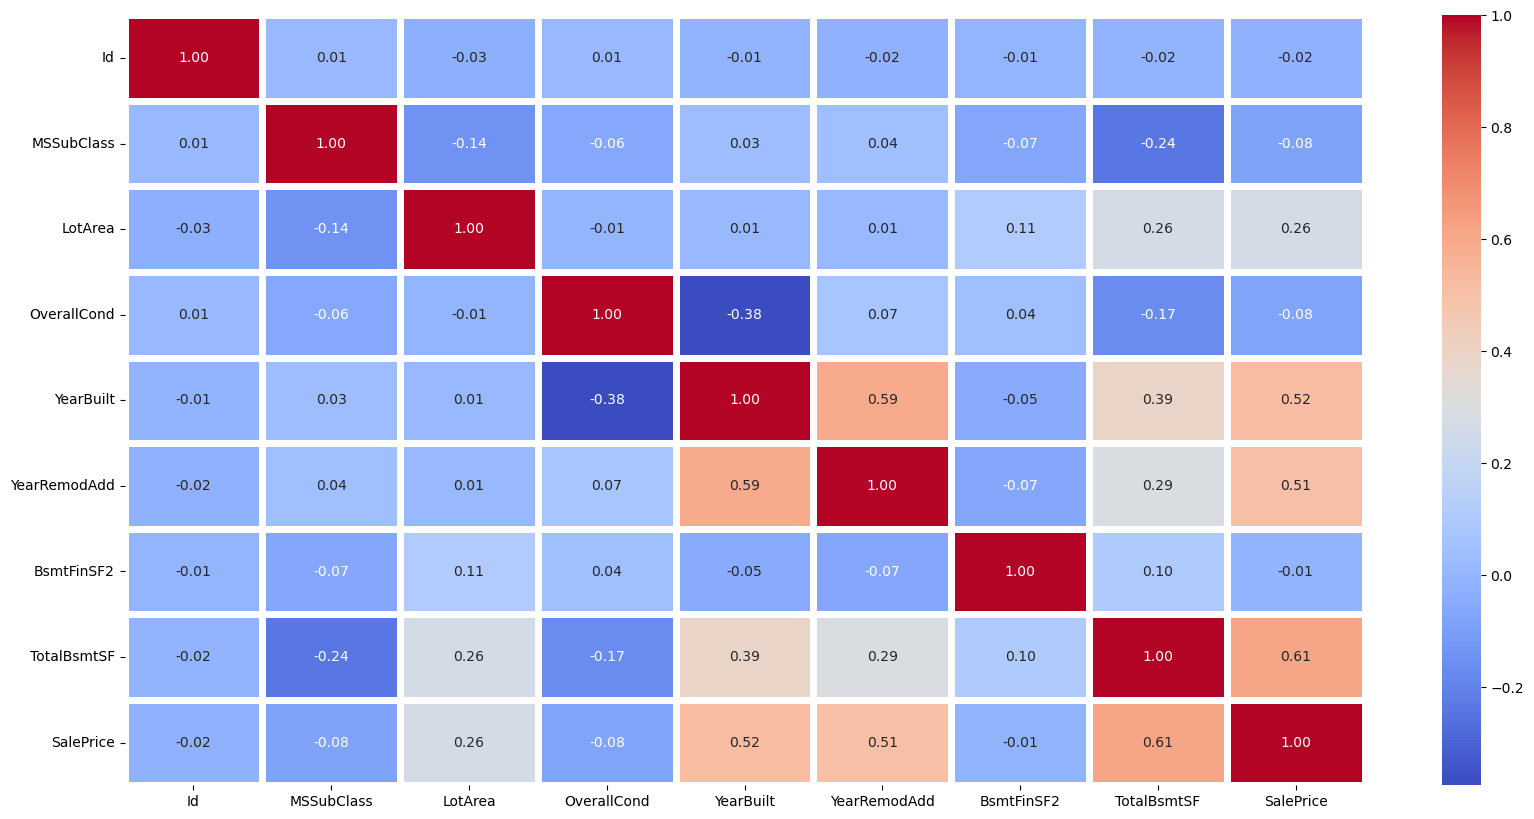

In [52]:
plt.figure(figsize=(20,10))
sns.heatmap(num_features.corr(),annot=True,fmt='.2f',cmap='coolwarm',linewidths=5)
plt.show()

In [53]:
num_features.corr().SalePrice.sort_values(ascending=False)

SalePrice       1.000000
TotalBsmtSF     0.613581
YearBuilt       0.522897
YearRemodAdd    0.507101
LotArea         0.263843
BsmtFinSF2     -0.011378
Id             -0.021917
OverallCond    -0.077856
MSSubClass     -0.084284
Name: SalePrice, dtype: float64

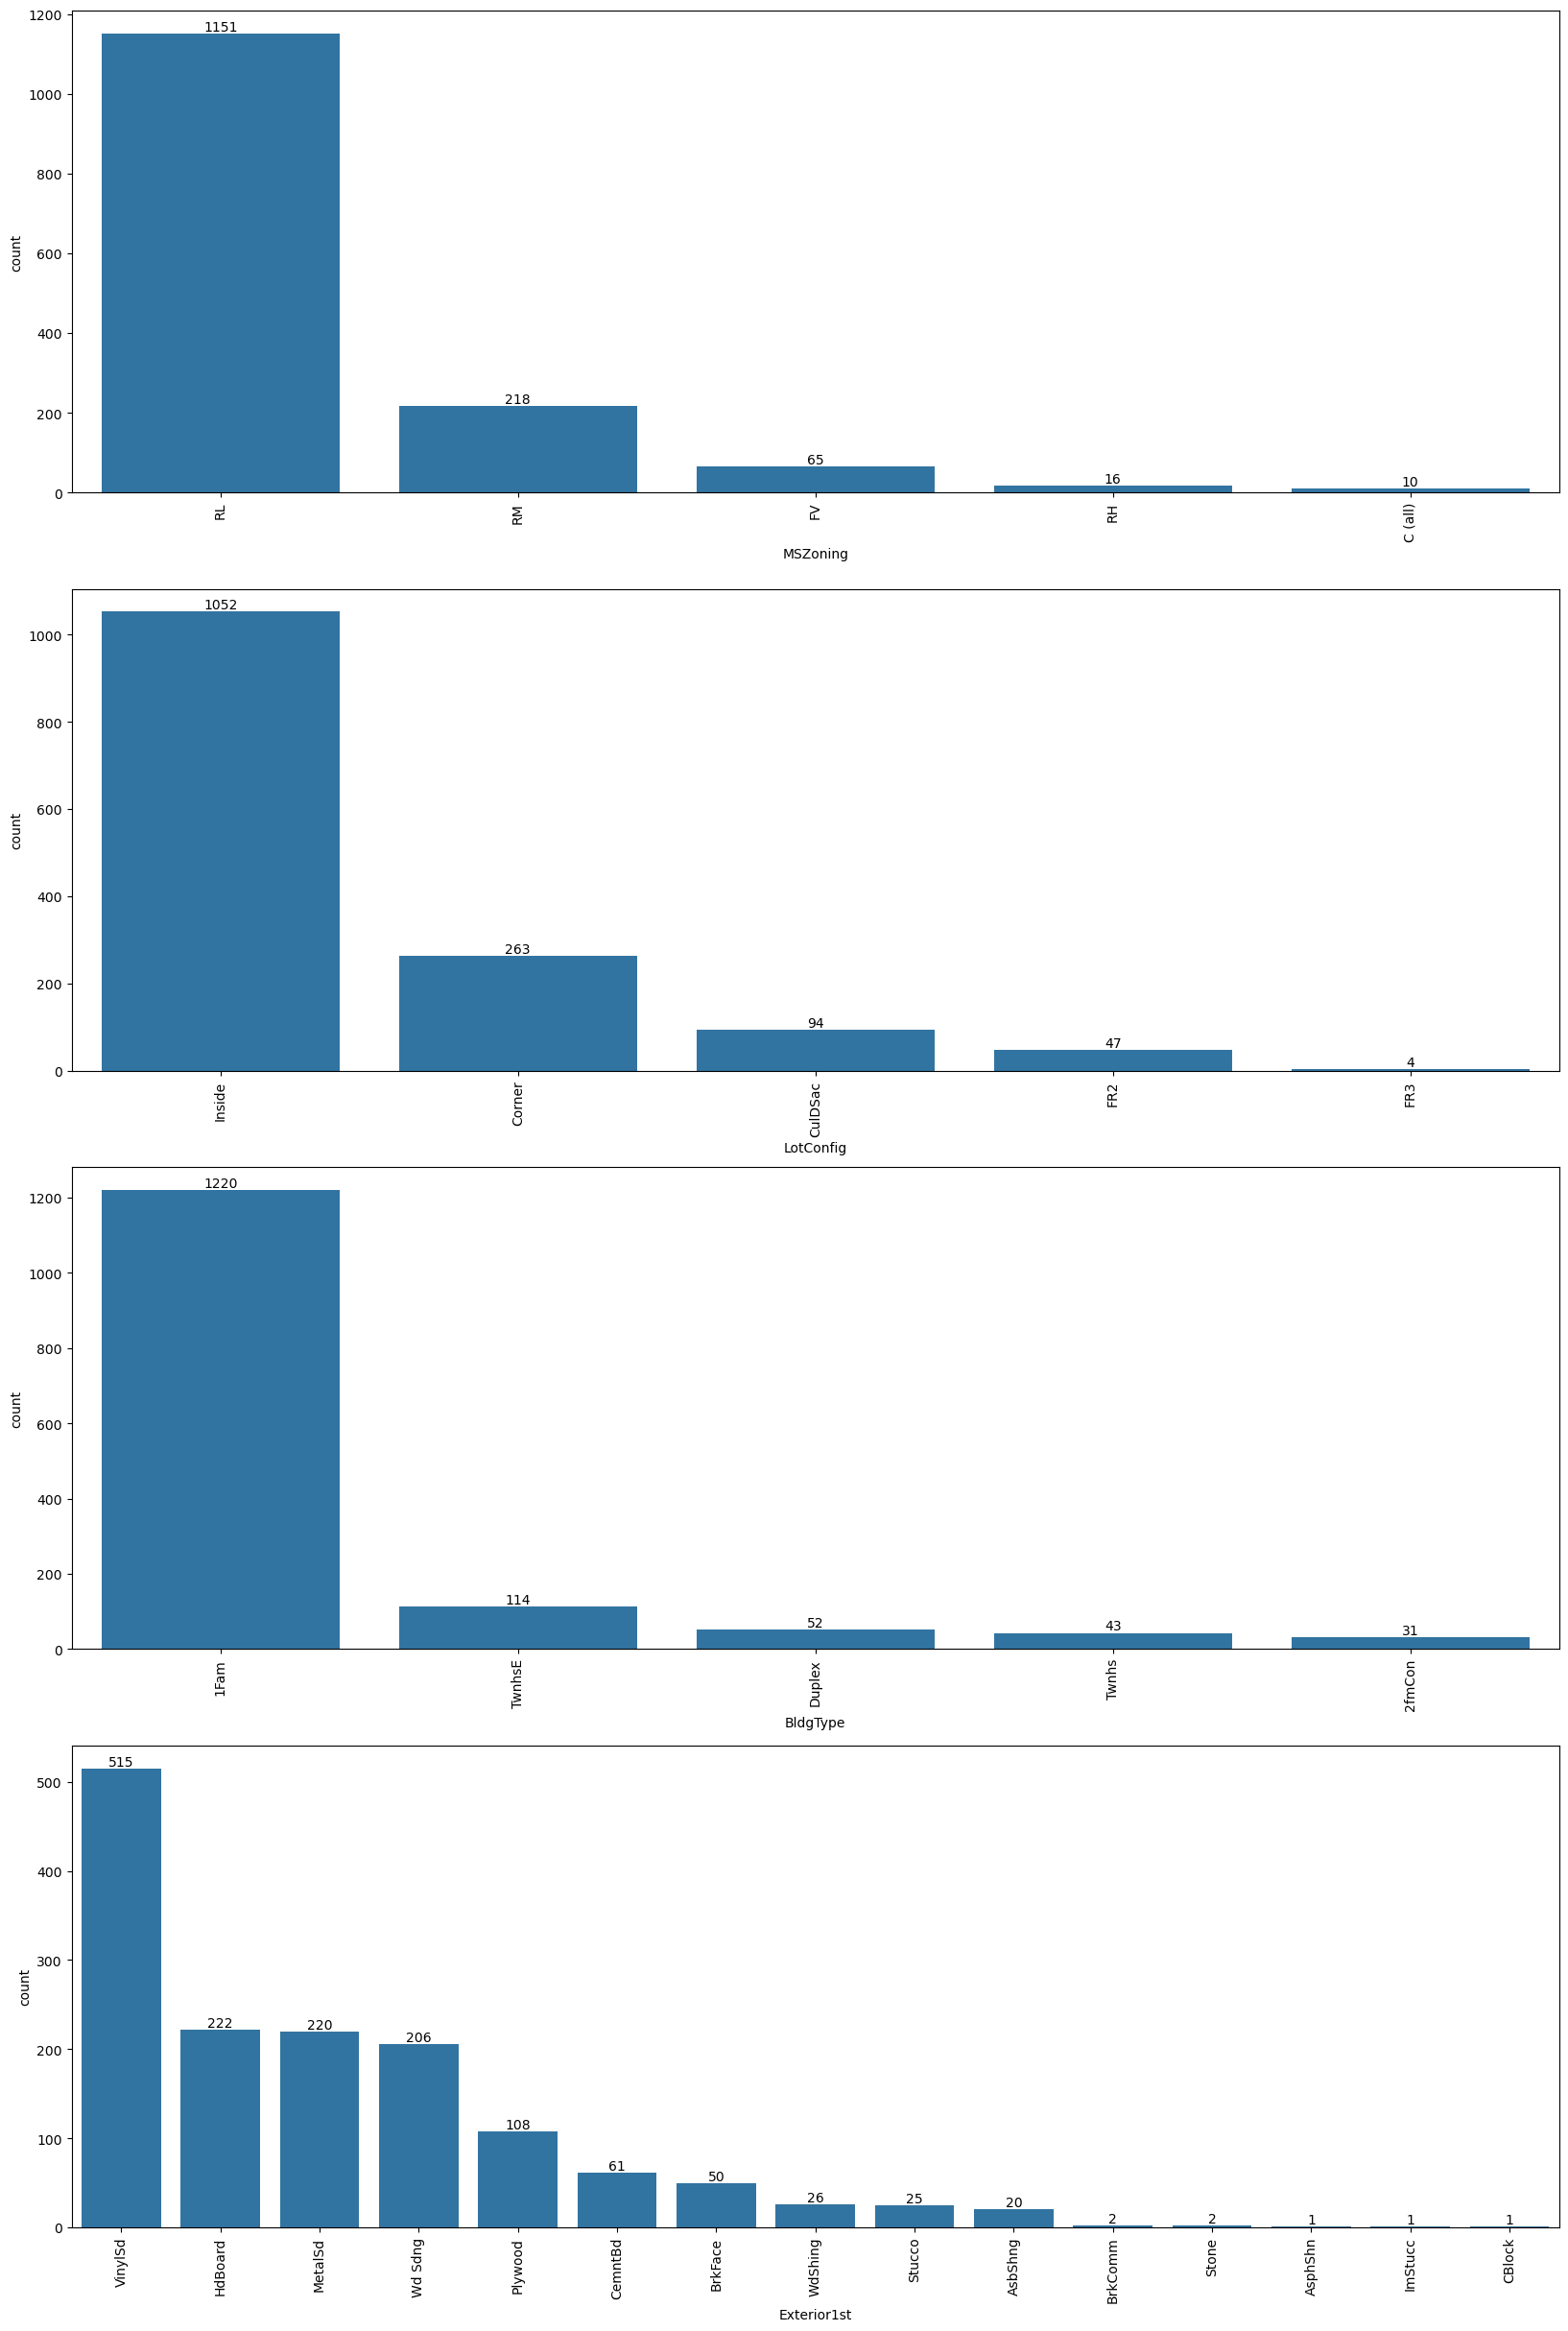

In [54]:
plt.figure(figsize=(20,30))
index = 1
for feature in cat_features.columns:
    ax = plt.subplot(4,1,index)
    sns.barplot(cat_features[feature].value_counts())
    plt.xticks(rotation=90)
    ax.bar_label(ax.containers[0])
    index += 1

In [55]:
df_clean = df_cleanna.drop(columns=['Id'])

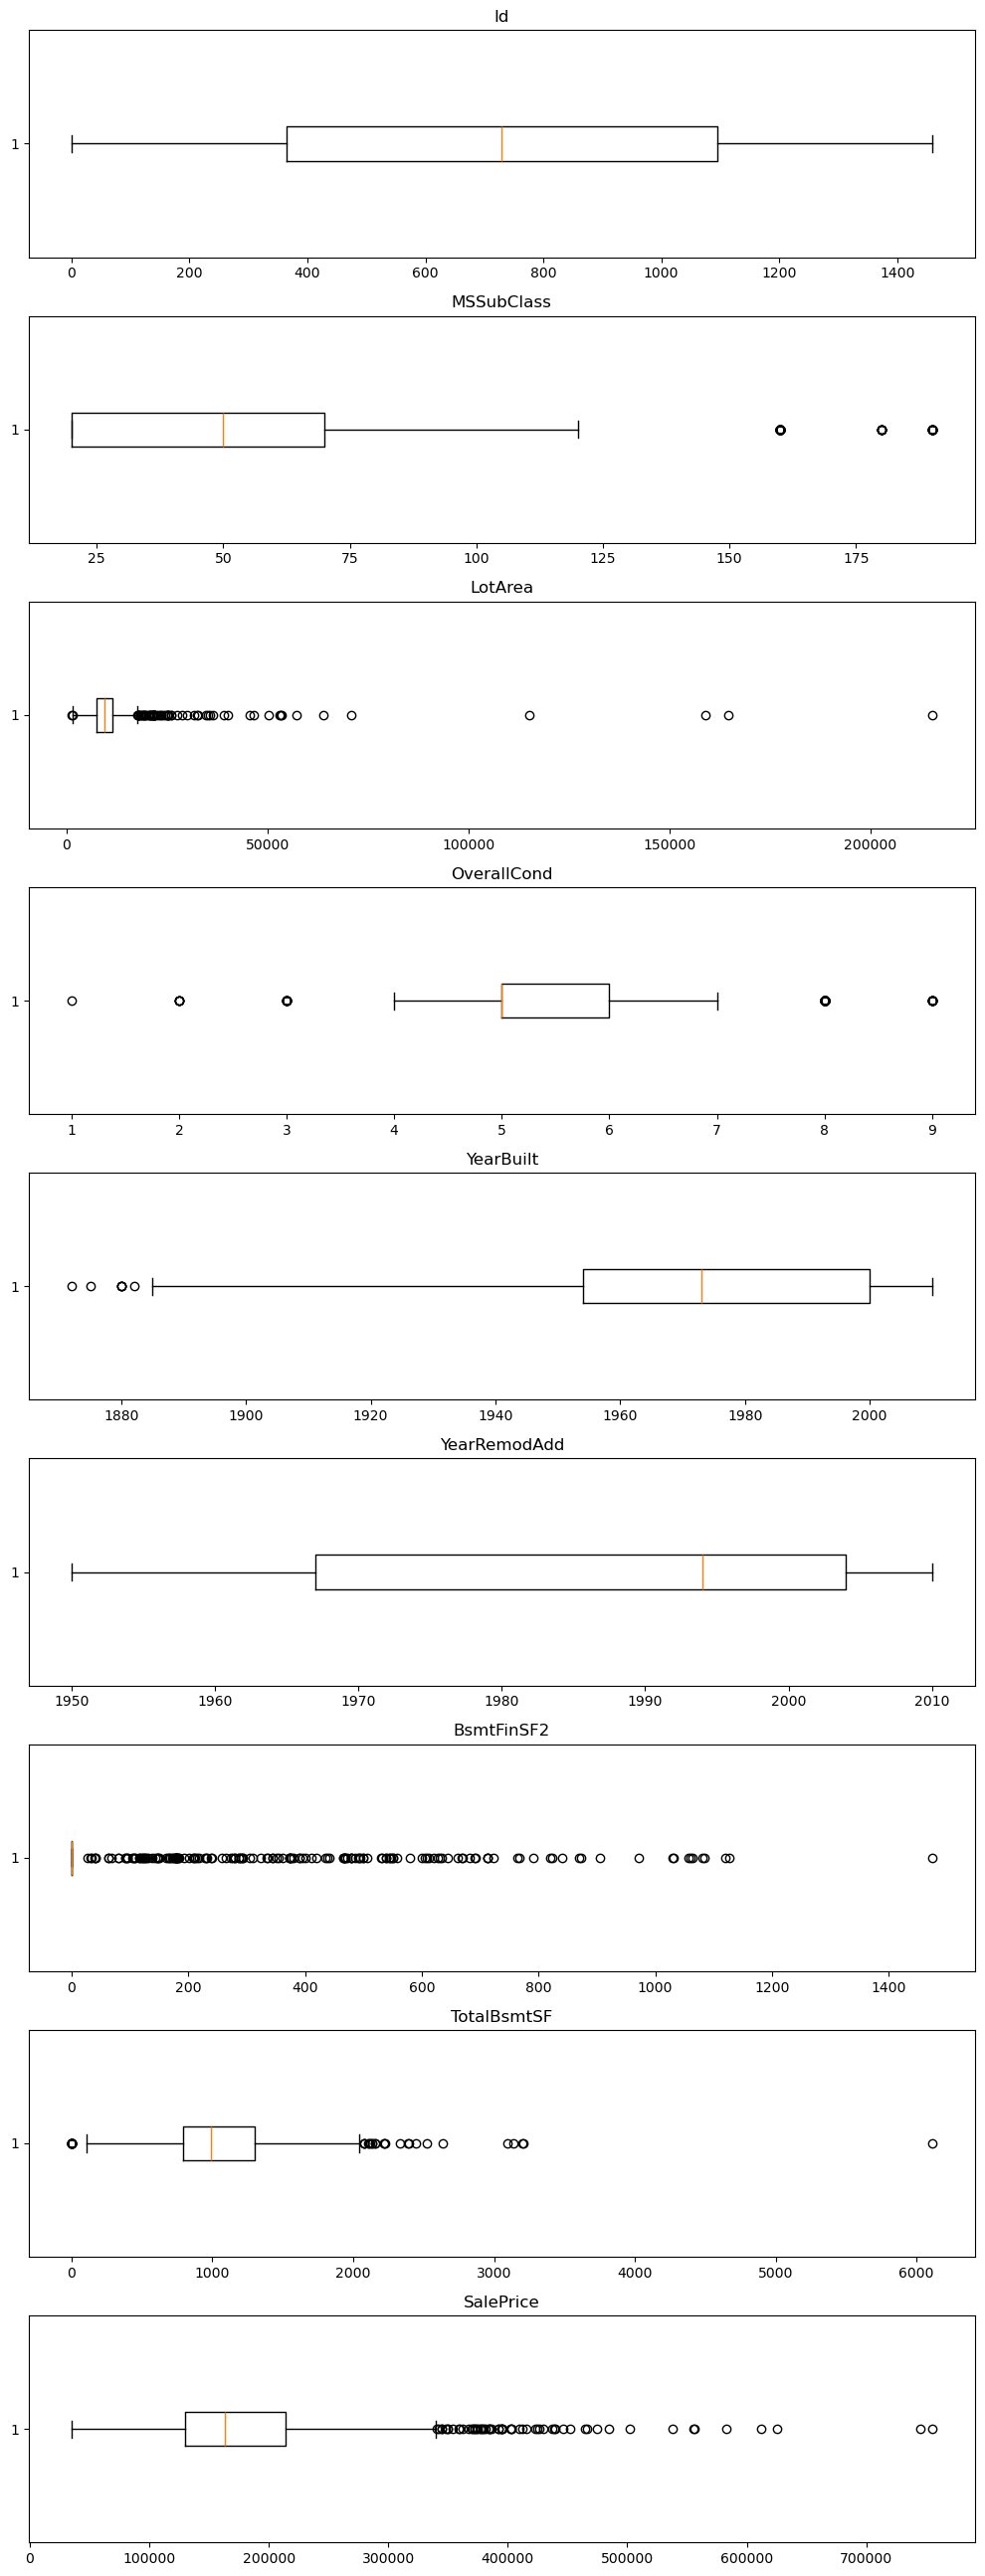

In [65]:
fig , axs = plt.subplots(len(num_features.columns),1,figsize=(10,26))

for i , col in enumerate(num_features.columns):
    axs[i].boxplot(num_features[col],vert=False)
    axs[i].set_title(col)
plt.tight_layout()

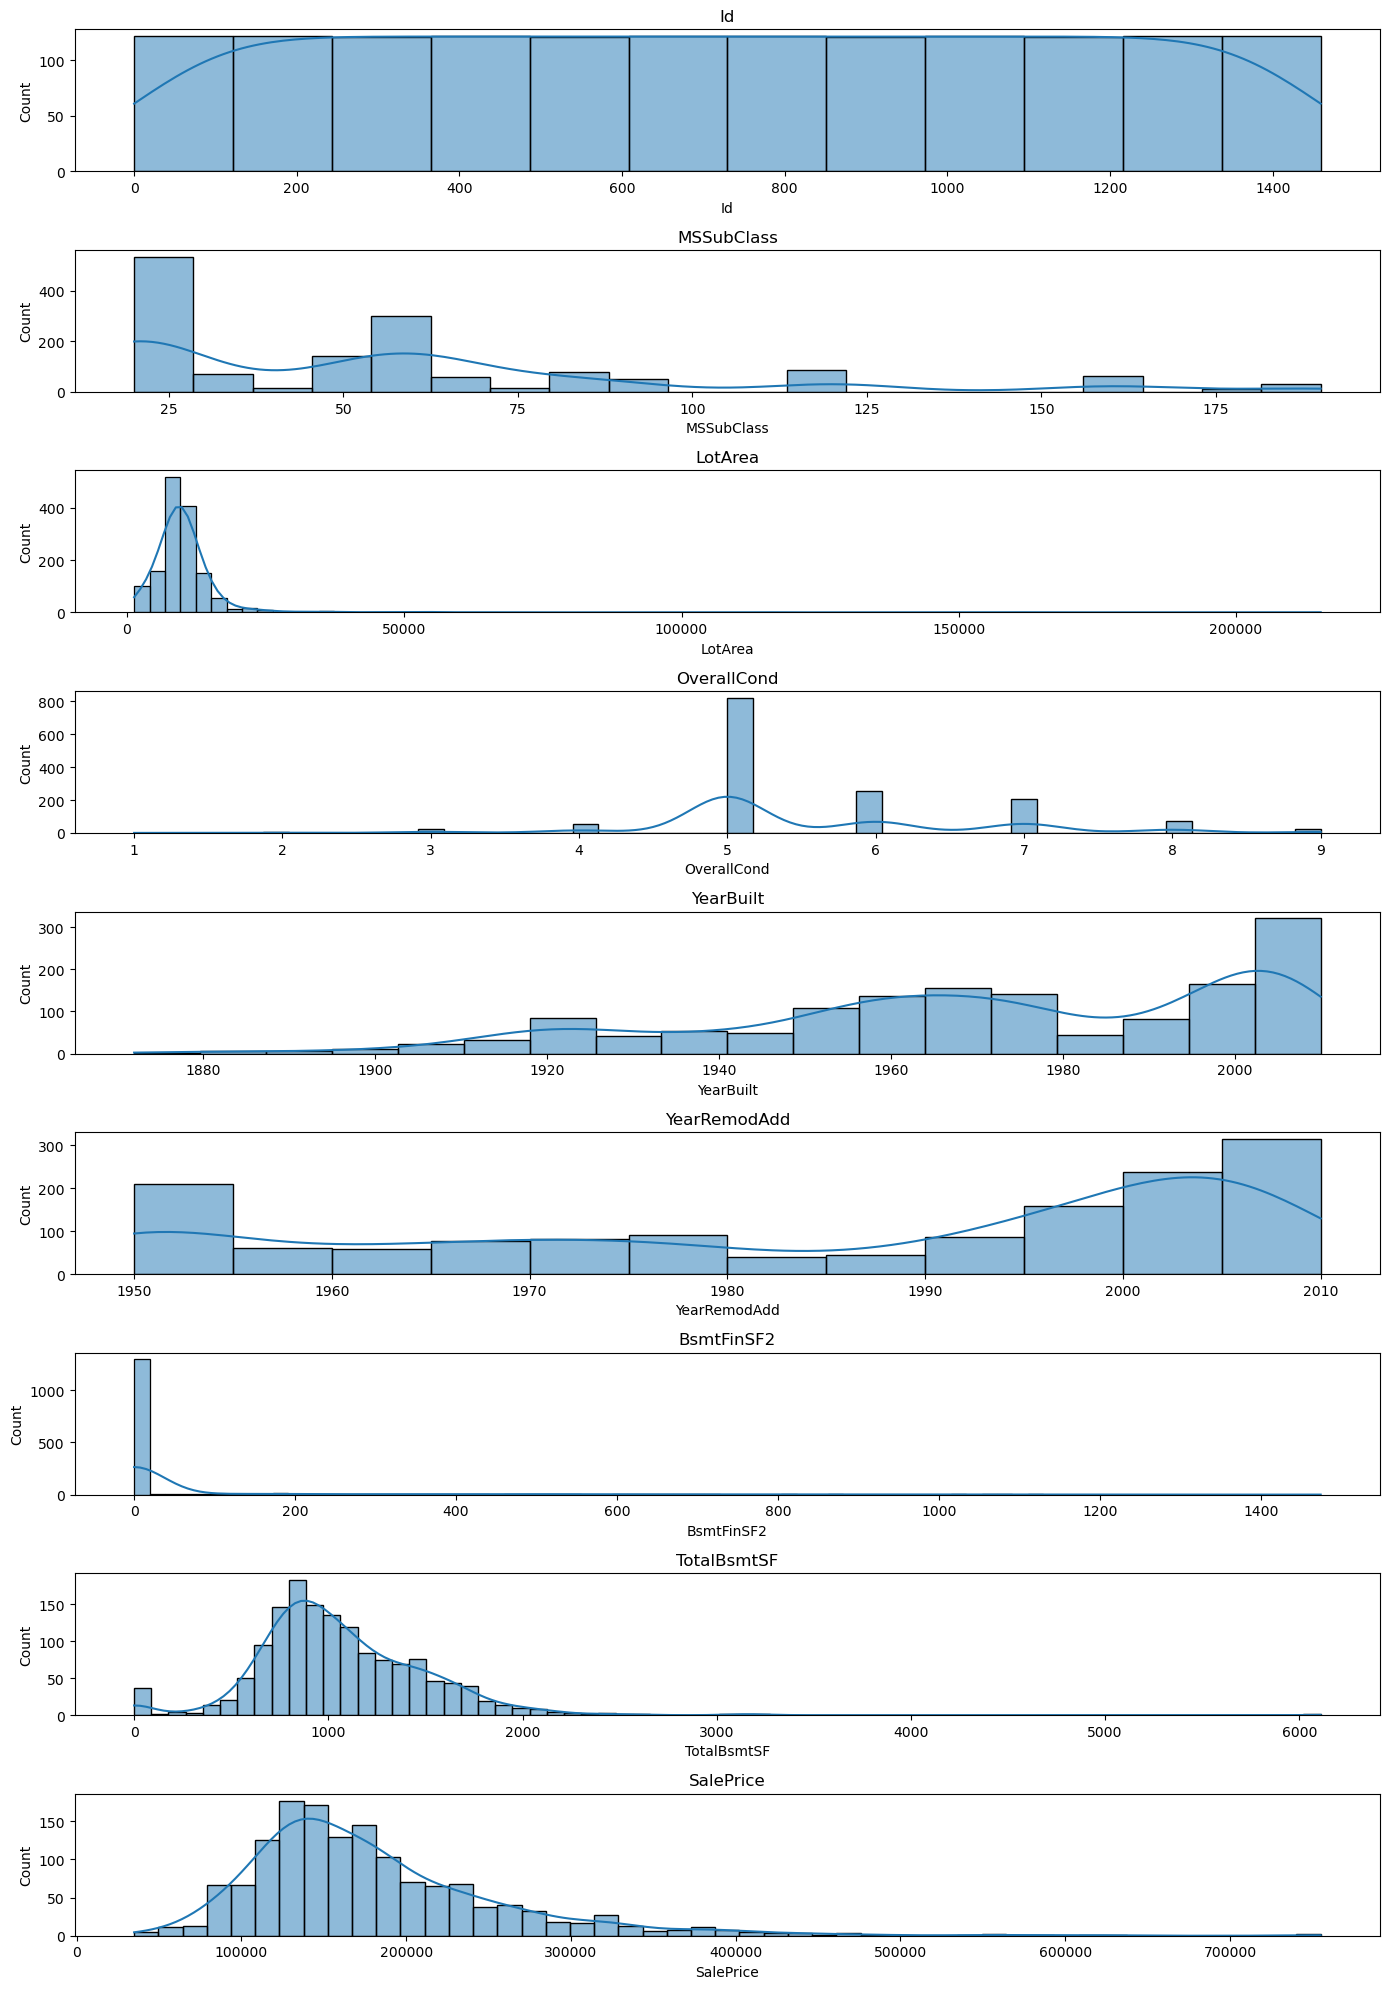

In [71]:
plt.figure(figsize=(14,20))
index = 1
for col in num_features.columns:
    plt.subplot(len(num_features.columns),1,index)
    sns.histplot(num_features[col],kde=True)
    plt.title(col)
    index+=1
plt.tight_layout()

In [13]:
df_clean = pd.get_dummies(df_clean,drop_first=True,dtype=np.int64)
df_clean.head()

,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,SalePrice,MSZoning_FV,MSZoning_RH,...,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing
0,60,8450,5,2003,2003,0.0,856.0,208500.0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,20,9600,8,1976,1976,0.0,1262.0,181500.0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,60,11250,5,2001,2002,0.0,920.0,223500.0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,70,9550,5,1915,1970,0.0,756.0,140000.0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,60,14260,5,2000,2000,0.0,1145.0,250000.0,0,0,...,0,0,0,0,0,0,0,1,0,0


## Get the Score of models

In [14]:
from sklearn.metrics import r2_score , mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV

In [15]:
X = df_clean.drop(columns=['SalePrice'])
y = df_clean.SalePrice
scaled = StandardScaler()
X_scaled = scaled.fit_transform(X)
X_train,X_test,y_train,y_test = train_test_split(X_scaled,y,test_size=0.2,random_state=44)
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(1168, 33) (292, 33) (1168,) (292,)


In [16]:
model_forest = RandomForestRegressor()
model_forest.fit(X_train,y_train)
forest_preds = model_forest.predict(X_test)
r2_score(y_test,forest_preds)

0.7943907504563043

In [17]:
model_linear = LinearRegression()
model_linear.fit(X_train,y_train)
linear_preds = model_linear.predict(X_test)
r2_score(y_test,linear_preds)

0.6791797461555394

In [41]:
models = [LinearRegression(),RandomForestRegressor(max_depth=10,max_features=0.8,min_samples_leaf=2,min_samples_split=2,n_estimators=200)]
for model in models:
    scores = cross_val_score(model,X_scaled,y,cv=5)
    print(f'model : {model}, scores : {scores} , final score : {np.mean(scores)}')

model : LinearRegression(), scores : [0.65901072 0.65113205 0.62301858 0.63037136 0.40365834] , final score : 0.5934382115092592
model : RandomForestRegressor(max_depth=10, max_features=0.8, min_samples_leaf=2,
                      n_estimators=200), scores : [0.78384652 0.77574407 0.80965877 0.78727677 0.73889034] , final score : 0.7790832944605837
